# Challenge · photo-compress

*Book 1 · Linear Algebra · Shelf I -- the book's closing challenge*

**The question.** Chapter 5 promised that a matrix whose singular values fall fast is well
described by a few of them. An image is a matrix. How few singular values does an image need --
and does it depend on *what* the image shows?

**The number.** For three kinds of image -- a photograph, a terrain model, a scanned document --
the rank $k$ that keeps 95 % of the energy ($\sum_{i\le k}\sigma_i^2 / \sum \sigma_i^2$), the rank that
reaches a PSNR of 30 dB (book 27, chapter 1), and how many numbers that rank costs against the
raw pixels.

**The data**, all offline: the portrait of Grace Hopper that ships with matplotlib (US Navy,
public domain), the Jacksboro fault elevation model that ships with matplotlib (USGS), and a
Swiss QR bill invented by the toolbox.

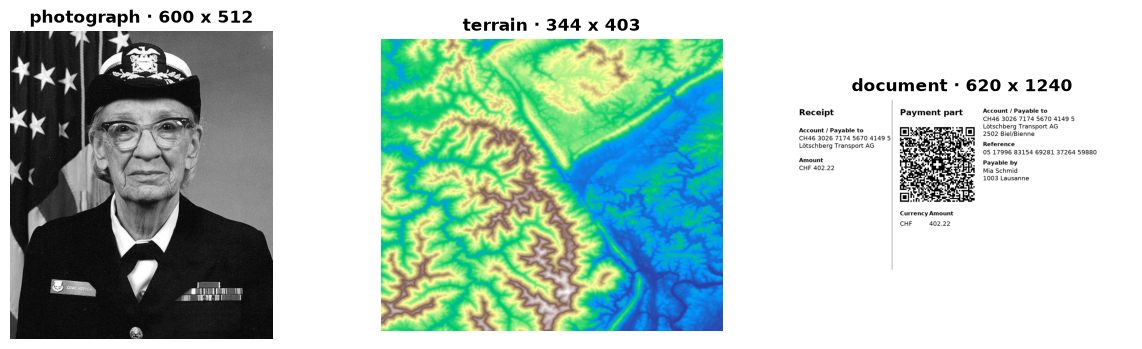

In [1]:
import json
from pathlib import Path

import matplotlib.cbook as cbook
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from ds_toolbox import qrbills as qb
from ds_toolbox import tracking, viz

viz.use_style()


def to_unit(a):
    a = a.astype(float)
    return (a - a.min()) / (a.max() - a.min())


photo = to_unit(np.asarray(Image.open(cbook.get_sample_data("grace_hopper.jpg")).convert("L")))
dem = to_unit(cbook.get_sample_data("jacksboro_fault_dem.npz")["elevation"])   # already loaded
document = to_unit(np.asarray(Image.fromarray(qb.render(qb.generate_bills(1, seed=11)[0])).convert("L")))
images = {"photograph": photo, "terrain": dem, "document": document}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, im) in zip(axes, images.items(), strict=True):
    ax.imshow(im, cmap="gray" if name != "terrain" else "terrain")
    ax.set_title(f"{name} · {im.shape[0]} x {im.shape[1]}")
    ax.axis("off")

## The singular values

Normalised by the largest, on a log scale. How fast each curve falls is the whole story.

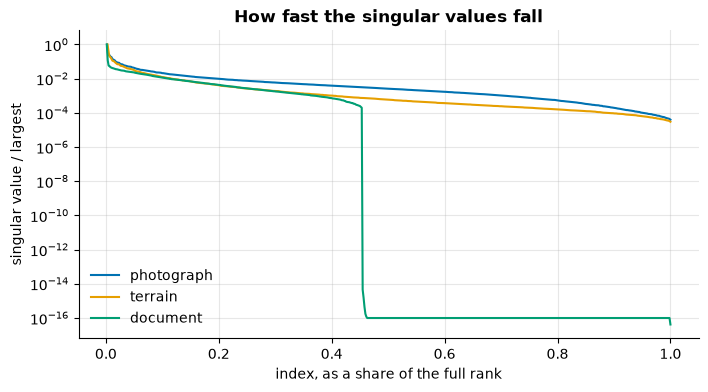

In [2]:
svd = {name: np.linalg.svd(im, full_matrices=False) for name, im in images.items()}
plt.figure(figsize=(8, 4))
for name, (_, s, _) in svd.items():
    plt.semilogy(np.arange(1, len(s) + 1) / len(s), s / s[0], label=name)
plt.xlabel("index, as a share of the full rank")
plt.ylabel("singular value / largest")
plt.legend()
plt.title("How fast the singular values fall");

## The measurement

In [3]:
def psnr(a, b):
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))   # images in [0, 1]


def rebuild(U, s, Vt, k):
    return np.clip((U[:, :k] * s[:k]) @ Vt[:k], 0, 1)


rows, curves = [], {}
for name, im in images.items():
    U, s, Vt = svd[name]
    energy = np.cumsum(s ** 2) / (s ** 2).sum()
    k95 = int(np.searchsorted(energy, 0.95) + 1)
    ks = np.unique(np.geomspace(1, len(s), 40).astype(int))
    p = np.array([psnr(im, rebuild(U, s, Vt, k)) for k in ks])
    curves[name] = (ks, p)
    k30 = int(ks[np.argmax(p >= 30)]) if (p >= 30).any() else None
    m, n = im.shape
    rows.append({"image": name, "full rank": len(s), "rank for 95 % energy": k95,
                 "rank for PSNR 30 dB": k30,
                 "numbers at that rank vs pixels": f"{k30 * (m + n + 1) / (m * n):.0%}" if k30 else "not reached"})
for r in rows:
    print(r)

{'image': 'photograph', 'full rank': 512, 'rank for 95 % energy': 15, 'rank for PSNR 30 dB': 88, 'numbers at that rank vs pixels': '32%'}
{'image': 'terrain', 'full rank': 344, 'rank for 95 % energy': 4, 'rank for PSNR 30 dB': 23, 'numbers at that rank vs pixels': '12%'}
{'image': 'document', 'full rank': 620, 'rank for 95 % energy': 2, 'rank for PSNR 30 dB': 101, 'numbers at that rank vs pixels': '24%'}


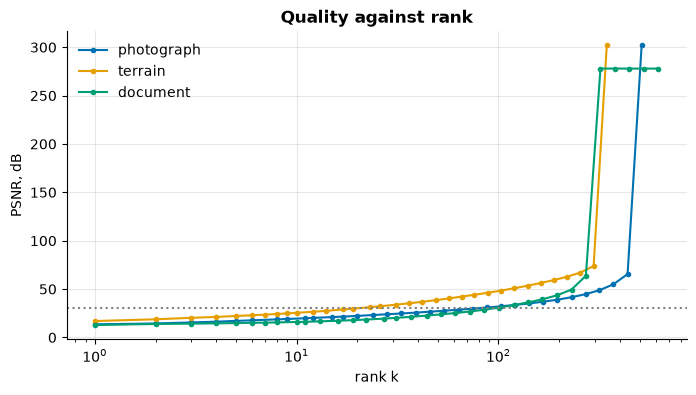

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, (ks, p) in curves.items():
    ax.semilogx(ks, p, marker=".", label=name)
ax.axhline(30, color="0.5", ls=":")
ax.set(xlabel="rank k", ylabel="PSNR, dB", title="Quality against rank")
ax.legend()

## Seeing the rank

Each image at the rank where it reaches 30 dB, and at a tenth of that.

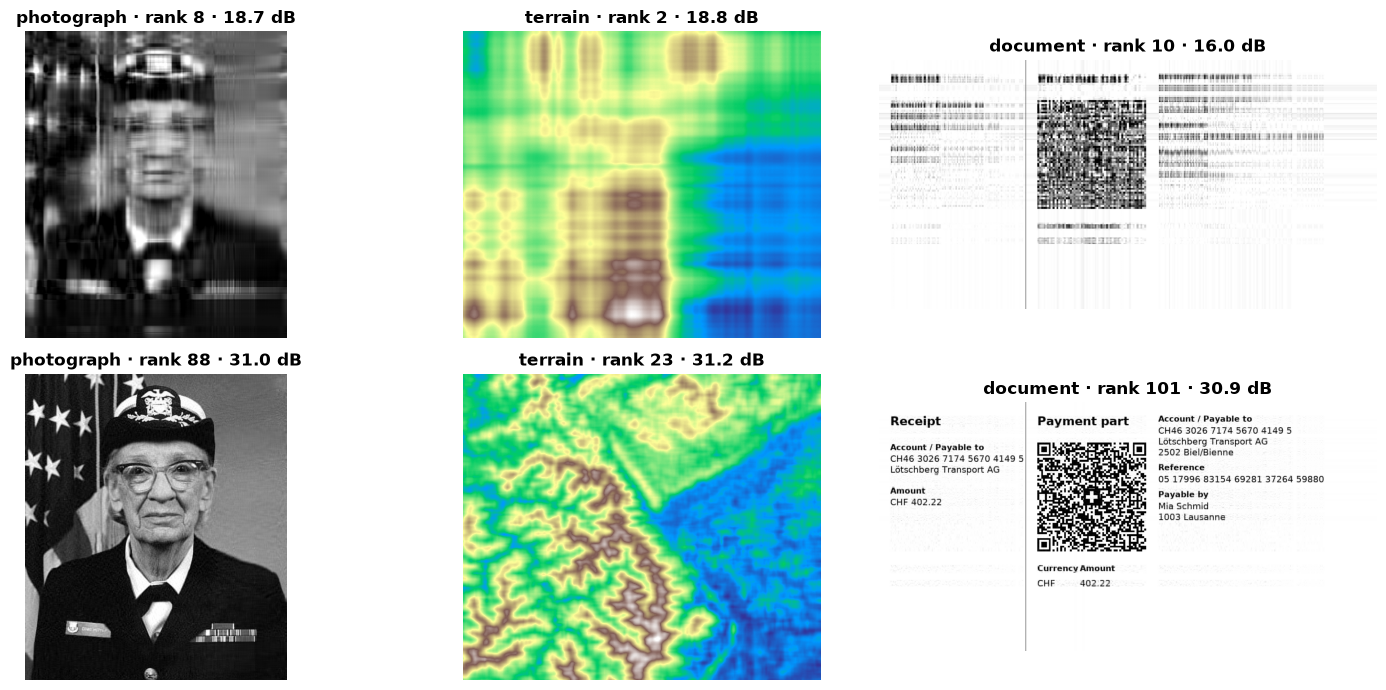

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for col, r in enumerate(rows):
    name, k = r["image"], r["rank for PSNR 30 dB"]
    U, s, Vt = svd[name]
    cmap = "terrain" if name == "terrain" else "gray"
    for row, kk in enumerate([max(1, k // 10), k]):
        axes[row, col].imshow(rebuild(U, s, Vt, kk), cmap=cmap)
        axes[row, col].set_title(f"{name} · rank {kk} · {psnr(images[name], rebuild(U, s, Vt, kk)):.1f} dB")
        axes[row, col].axis("off")
fig.tight_layout()

## Energy is not quality

The 95 %-energy rank and the 30 dB rank disagree, and by different amounts per image. Energy is
measured on the raw pixel values, so the large, flat areas -- the white paper of the document, the
broad slope of the terrain -- dominate it. PSNR is set by what remains after those are captured:
the edges and textures. A rule of thumb from one kind of image does not transfer to another.

In [6]:
HERE = Path.cwd()
summary = {"challenge": "photo-compress", "metric": "rank for 95 % energy and for PSNR 30 dB",
           "results": rows}
(HERE / "results.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
_run = tracking.log_run("photo-compress", {"images": len(images)},
                 {f"k30_{r['image']}": float(r["rank for PSNR 30 dB"] or -1) for r in rows}, root=HERE,
                 use_mlflow=False)

## What the number says

- **The terrain is the most compressible.** Rank 23 reaches 30 dB -- 12 % of the numbers the
  pixels take. A smooth surface is close to low-rank, the case chapter 5 described.
- **The photograph needs rank 88**, a third of the numbers: a face and a uniform have texture at
  every scale.
- **The document is the trap.** Two components already hold 95 % of its energy -- the white
  paper -- yet it needs rank 101 for 30 dB, because text is sharp edges at every position, and the
  SVD describes the image with whole rows and columns at once. Energy and quality disagree by a
  factor of about 6 on the photograph and the terrain and of 50 on the document.
- **The SVD explains compression; it is not a good codec.** Its numbers are floats, and JPEG
  stores the same kind of document (book 27, chapter 1) about 28 times smaller at 39.5 dB, because
  it works on small local blocks. The low-rank idea earns its keep where the structure really is
  global -- a recommender's ratings matrix (book 31), the principal components of a table (chapter 6).

**Back to the book:** [Book 1 · Linear Algebra](../README.md)